In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully.")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully.


In [2]:
def project_root(marker=".git"):
    p = Path.cwd().resolve()
    for parent in [p, *p.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"No {marker} found above {p}")

ROOT = project_root()
DATA = ROOT / "data"

In [3]:
DATA_DIR = Path("/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Learning/notebooks")

clinical = pd.read_csv(DATA /"raw/train_clinical_data.csv")
proteins = pd.read_csv(DATA /"raw/train_proteins.csv")
peptides = pd.read_csv(DATA /"raw/train_peptides.csv")
supplemental = pd.read_csv(DATA /"raw/supplemental_clinical_data.csv")

print("All datasets loaded  successfully.")

All datasets loaded  successfully.


In [4]:
clinical['visit_id'].nunique()

2615

In [5]:
peptide_wide = peptides.pivot_table(
    index="visit_id",
    columns="Peptide",
    values="PeptideAbundance",
    aggfunc="first"
)

print("Peptide data in wide format:")
print("Rows (visits):", peptide_wide.shape[0])
print("Columns (peptides):", peptide_wide.shape[1])

peptide_wide.head()


Peptide data in wide format:
Rows (visits): 1113
Columns (peptides): 968


Peptide,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,AAFTEC(UniMod_4)C(UniMod_4)QAADK,AANEVSSADVK,AATGEC(UniMod_4)TATVGKR,AATVGSLAGQPLQER,AAVYHHFISDGVR,ADDKETC(UniMod_4)FAEEGK,ADDKETC(UniMod_4)FAEEGKK,ADDLGKGGNEESTKTGNAGSR,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
visit_id,,,,,,,,,,,,,,,,,,,,,
10053_0,6580710.0,31204.4,7735070.0,NaN,NaN,NaN,46620.3,236144.0,NaN,NaN,...,202274.0,NaN,4401830.0,77482.6,583075.0,76705.7,104260.0,530223.0,NaN,7207.30
10053_12,6333510.0,52277.6,5394390.0,NaN,NaN,NaN,57554.5,108298.0,45885.4,NaN,...,201009.0,NaN,5001750.0,36745.3,355643.0,92078.1,123254.0,453883.0,49281.9,25332.80
10053_18,7129640.0,61522.0,7011920.0,35984.7,17188.0,19787.3,36029.4,708729.0,5067790.0,30838.2,...,220728.0,NaN,5424380.0,39016.0,496021.0,63203.6,128336.0,447505.0,52389.1,21235.70
10138_12,7404780.0,46107.2,10610900.0,NaN,20910.2,66662.3,55253.9,79575.5,6201210.0,26720.0,...,188362.0,9433.71,3900280.0,48210.3,328482.0,89822.1,129964.0,552232.0,65657.8,9876.98
10138_24,13788300.0,56910.3,6906160.0,13785.5,11004.2,63672.7,36819.8,34160.9,2117430.0,15645.2,...,206187.0,6365.15,3521800.0,69984.6,496737.0,80919.3,111799.0,NaN,56977.6,4903.09


In [6]:
#Merging the two datasets (clinical data and the peptide data)

merged_data = pd.merge(clinical, peptide_wide, on='visit_id', how='inner')
display(merged_data.head())
print(merged_data.describe())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,8984260.0,53855.6,...,201158.0,16492.3,3810270.0,106894.0,580667.0,131155.0,165851.0,437305.0,46289.2,14898.4
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,8279770.0,45251.9,...,171079.0,13198.8,4119520.0,113385.0,514861.0,103512.0,144607.0,457891.0,40047.7,20703.9
2,55_12,55,12,10.0,10.0,41.0,0.0,On,8382390.0,53000.9,...,231772.0,17873.8,5474140.0,116286.0,711815.0,136943.0,181763.0,452253.0,54725.1,21841.1
3,55_36,55,36,17.0,18.0,51.0,0.0,On,10671500.0,58108.4,...,185290.0,18580.5,2659660.0,90936.9,679163.0,128593.0,203680.0,498621.0,52792.7,13973.7
4,942_6,942,6,8.0,2.0,21.0,NaN,NaN,6177730.0,42682.6,...,226314.0,6399.8,NaN,57571.4,480951.0,80001.2,79661.9,573300.0,48005.8,15674.1


         patient_id  visit_month      updrs_1      updrs_2      updrs_3  \
count   1068.000000  1068.000000  1068.000000  1068.000000  1058.000000   
mean   32673.328652    26.744382     6.566479     5.821161    17.300567   
std    18612.372744    22.839426     5.330702     5.931414    15.016371   
min       55.000000     0.000000     0.000000     0.000000     0.000000   
25%    16574.000000     6.000000     2.000000     1.000000     2.000000   
50%    29365.000000    24.000000     5.000000     4.000000    16.000000   
75%    50611.000000    48.000000     9.000000     9.000000    28.000000   
max    65043.000000   108.000000    33.000000    29.000000    78.000000   

          updrs_4  AADDTWEPFASGK  \
count  569.000000   1.025000e+03   
mean     1.908612   7.822847e+06   
std      3.077419   3.748363e+06   
min      0.000000   3.986000e+05   
25%      0.000000   5.275490e+06   
50%      0.000000   7.277070e+06   
75%      3.000000   9.768580e+06   
max     20.000000   3.431410e+07   


In [7]:
merged_data_sorted = merged_data.sort_values(by='patient_id', ascending=True)
display(merged_data_sorted.head())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,8984260.0,53855.6,...,201158.0,16492.3,3810270.0,106894.0,580667.0,131155.0,165851.0,437305.0,46289.2,14898.4
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,8279770.0,45251.9,...,171079.0,13198.8,4119520.0,113385.0,514861.0,103512.0,144607.0,457891.0,40047.7,20703.9
2,55_12,55,12,10.0,10.0,41.0,0.0,On,8382390.0,53000.9,...,231772.0,17873.8,5474140.0,116286.0,711815.0,136943.0,181763.0,452253.0,54725.1,21841.1
3,55_36,55,36,17.0,18.0,51.0,0.0,On,10671500.0,58108.4,...,185290.0,18580.5,2659660.0,90936.9,679163.0,128593.0,203680.0,498621.0,52792.7,13973.7
4,942_6,942,6,8.0,2.0,21.0,NaN,NaN,6177730.0,42682.6,...,226314.0,6399.8,NaN,57571.4,480951.0,80001.2,79661.9,573300.0,48005.8,15674.1


In [8]:
updrs_columns = ['updrs_1', 'updrs_2', 'updrs_3', 'updrs_4']
peptide_columns = peptide_wide.columns.tolist()

# Apply linear interpolation to UPDRS columns
for col in updrs_columns:
    if col in merged_data_sorted.columns:
        merged_data_sorted[col] = merged_data_sorted[col].interpolate(method='linear')

# Apply linear interpolation to peptide columns
for col in peptide_columns:
    if col in merged_data_sorted.columns:
        merged_data_sorted[col] = merged_data_sorted[col].interpolate(method='linear')

# Display the head of the DataFrame after interpolation
display(merged_data_sorted.head())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,8984260.0,53855.6,...,201158.0,16492.3,3810270.0,106894.0,580667.0,131155.0,165851.0,437305.0,46289.2,14898.4
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,8279770.0,45251.9,...,171079.0,13198.8,4119520.0,113385.0,514861.0,103512.0,144607.0,457891.0,40047.7,20703.9
2,55_12,55,12,10.0,10.0,41.0,0.0,On,8382390.0,53000.9,...,231772.0,17873.8,5474140.0,116286.0,711815.0,136943.0,181763.0,452253.0,54725.1,21841.1
3,55_36,55,36,17.0,18.0,51.0,0.0,On,10671500.0,58108.4,...,185290.0,18580.5,2659660.0,90936.9,679163.0,128593.0,203680.0,498621.0,52792.7,13973.7
4,942_6,942,6,8.0,2.0,21.0,0.0,NaN,6177730.0,42682.6,...,226314.0,6399.8,1516983.5,57571.4,480951.0,80001.2,79661.9,573300.0,48005.8,15674.1



Performing Lasso regression for target: updrs_3


/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.209838e+03, tolerance: 2.373e+01
  model = cd_fast.enet_coordinate_descent(
/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.154828e+03, tolerance: 2.373e+01
  model = cd_fast.enet_coordinate_descent(
/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Lea

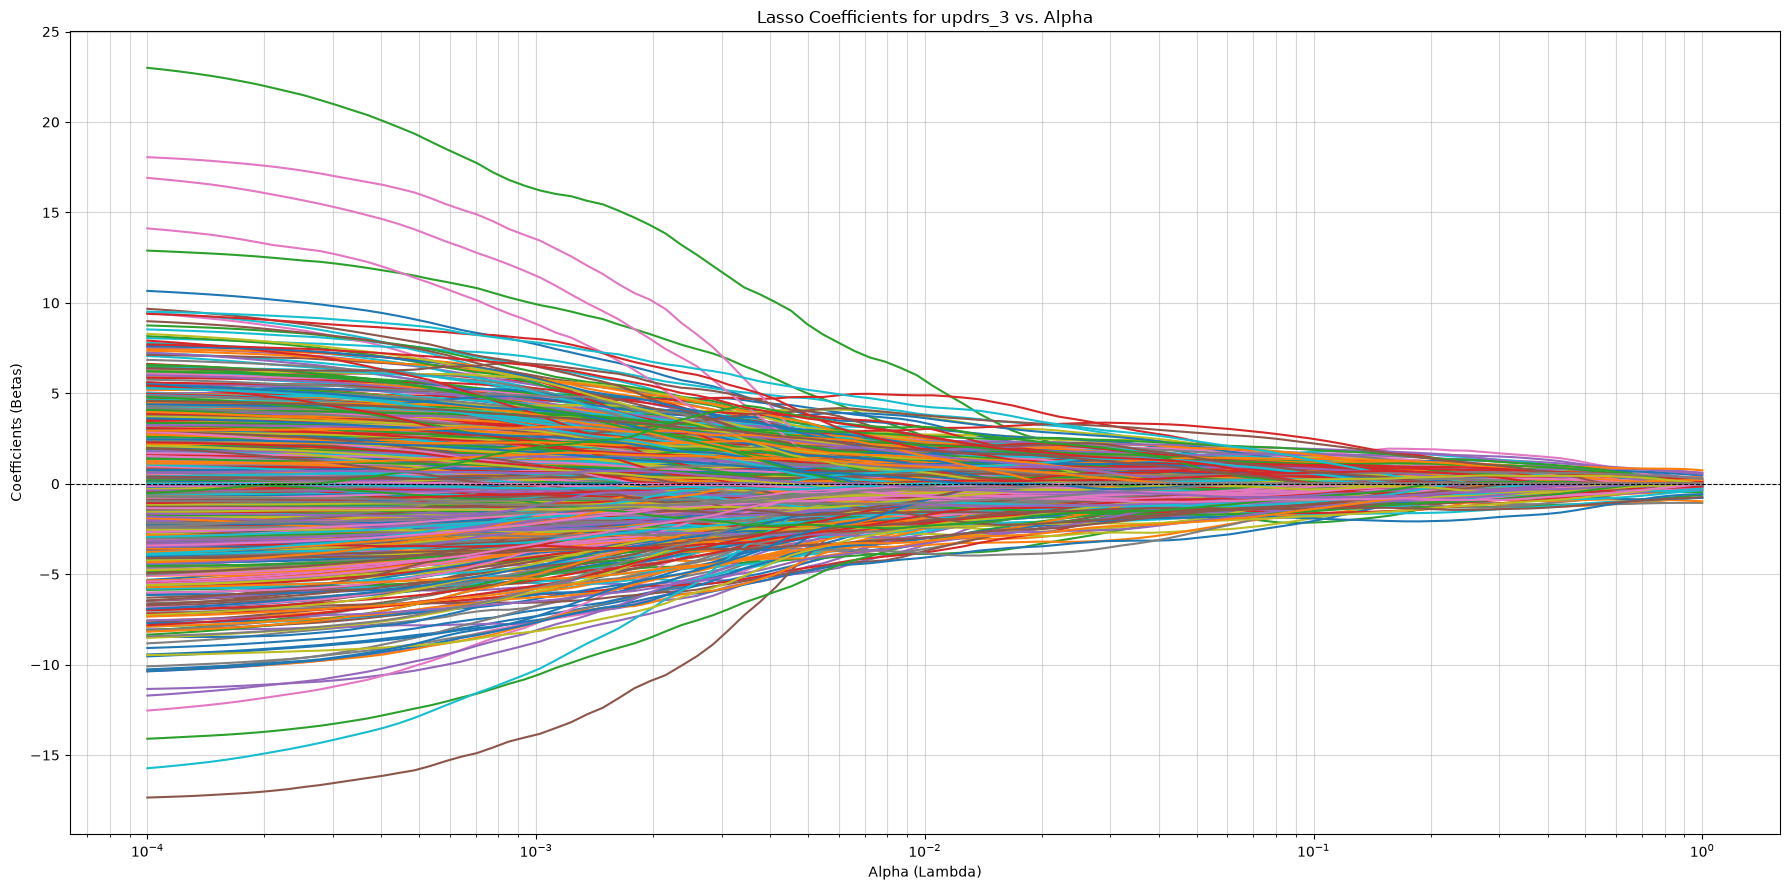

In [13]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Define alpha values for Lasso (lambda)
alphas = np.logspace(-4, 0, 100) # 100 values from 0.0001 to 1

# Prepare features (peptide scores) from the merged and interpolated data
X_peptides = merged_data_sorted[peptide_columns]

# Initialize StandardScaler
scaler = StandardScaler()

# Iterate through each UPDRS score to perform Lasso regression
for updrs_col in updrs_columns:
    if updrs_col == "updrs_3":
        print(f"\nPerforming Lasso regression for target: {updrs_col}")

        # Prepare the target variable
        y_updrs = merged_data_sorted[updrs_col]

        # Combine X and y to drop NaNs consistently for the current target
        # This ensures that only rows with complete data for both peptides and the current UPDRS score are used
        temp_df = pd.concat([X_peptides, y_updrs], axis=1).dropna()

        if temp_df.empty:
            print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
            continue

        X_clean = temp_df[peptide_columns]
        y_clean = temp_df[updrs_col]

        # Scale the peptide features
        X_scaled = scaler.fit_transform(X_clean)

        # Store coefficients for each alpha value
        coefs = []
        for a in alphas:
            # Initialize Lasso model with current alpha and increased max_iter for convergence
            lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
            lasso.fit(X_scaled, y_clean)
            coefs.append(lasso.coef_)

        # Plot coefficients for the current UPDRS score
        fig, ax = plt.subplots(figsize=(18, 9)) # Increased figure size
        ax.plot(alphas, coefs)
        ax.set_xscale('log')
        plt.xlabel('Alpha (Lambda)')
        plt.ylabel('Coefficients (Betas)')
        plt.title(f'Lasso Coefficients for {updrs_col} vs. Alpha')
        # Place legend outside the plot area for better readability
        #ax.legend(peptide_columns, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
        plt.axhline(0, color='black', linestyle='--', linewidth=0.8) # Add a horizontal line at 0
        plt.grid(True, which="both", ls="-", alpha=0.5)
        plt.tight_layout() # Adjust layout to prevent labels/legend from being cut off
        plt.show()

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# Define the number of folds for cross-validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Store MSEs for plotting later
all_mses = {}

# Iterate through each UPDRS score
for updrs_col in updrs_columns:
    if updrs_col == "updrs_3":
        print(f"\nPerforming K-fold cross-validation for target: {updrs_col}")

        # Prepare the target variable
        y_updrs = merged_data_sorted[updrs_col]

        # Combine X and y to drop NaNs consistently for the current target
        temp_df = pd.concat([X_peptides, y_updrs], axis=1).dropna()

        if temp_df.empty:
            print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
            continue

        X_clean = temp_df[peptide_columns]
        y_clean = temp_df[updrs_col]

        # Dictionary to store MSEs for each alpha across folds
        mse_for_alphas = {a: [] for a in alphas}

        # Perform K-fold cross-validation
        for fold, (train_index, test_index) in enumerate(kf.split(X_clean)):
            # Split data into training and testing sets for the current fold
            X_train, X_test = X_clean.iloc[train_index], X_clean.iloc[test_index]
            y_train, y_test = y_clean.iloc[train_index], y_clean.iloc[test_index]

            # Initialize and fit StandardScaler on the training data
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            # Iterate through each alpha value
            for a in alphas:
                # Initialize and fit Lasso model
                lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
                lasso.fit(X_train_scaled, y_train)

                # Make predictions on the scaled test set
                y_pred = lasso.predict(X_test_scaled)

                # Calculate Mean Squared Error
                mse = mean_squared_error(y_test, y_pred)
                mse_for_alphas[a].append(mse)

        # Calculate the average MSE for each alpha across all folds
        avg_mses = {a: np.mean(mses) for a, mses in mse_for_alphas.items()}
        all_mses[updrs_col] = avg_mses

        # Plot MSE vs. Alpha
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.plot(list(avg_mses.keys()), list(avg_mses.values()))
        ax.set_xscale('log')
        plt.xlabel('Alpha (Lambda)')
        plt.ylabel('Average Mean Squared Error (MSE)')
        plt.title(f'Average MSE vs. Alpha for {updrs_col} (K-fold Cross-Validation)')
        plt.grid(True, which="both", ls="-", alpha=0.5)
        plt.tight_layout()
        plt.show()


Performing K-fold cross-validation for target: updrs_3


/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.098538e+02, tolerance: 1.941e+01
  model = cd_fast.enet_coordinate_descent(
/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.242524e+02, tolerance: 1.941e+01
  model = cd_fast.enet_coordinate_descent(
/Users/parasgupta/Documents/Projects/NCSU-Sem3/ST-563 Statistical Learning/Project_Statistical_Lea

In [ ]:
optimal_alphas = {}
for updrs_col, mses in all_mses.items():
    # Find the alpha with the minimum MSE
    if updrs_col == "updrs_3"
        min_mse_alpha = min(mses, key=mses.get)
        optimal_alphas[updrs_col] = min_mse_alpha

print("Optimal Alpha (Lambda) for each UPDRS score:")
for updrs_col, alpha in optimal_alphas.items():
    if updrs_col == "updrs_3"
        print(f"  {updrs_col}: {alpha:.6f}")

In [ ]:
print("Minimum MSE for each UPDRS score:")
for updrs_col, mses in all_mses.items():
    if updrs_col == "updrs_3"
        min_mse_value = min(mses.values())
        print(f"  {updrs_col}: {min_mse_value:.6f}")


In [ ]:
peptide_stickiness = {}

for updrs_col in updrs_columns:
    if updrs_col == "updrs_3"
        print(f"\nAnalyzing peptide stickiness for {updrs_col}")

        y_updrs = merged_data_sorted[updrs_col]
        temp_df = pd.concat([X_peptides, y_updrs], axis=1).dropna()

        if temp_df.empty:
            print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
            continue

        X_clean = temp_df[peptide_columns]
        y_clean = temp_df[updrs_col]

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_clean)

        # Dictionary to store the highest alpha at which a peptide's coefficient is non-zero
        # Initialize with 0 (or a very small number) for all peptides
        last_non_zero_alpha = {pept: 0 for pept in peptide_columns}

        # Sort alphas to iterate from smallest to largest to track when coefficients become non-zero
        # However, to find the 'highest alpha for which coefficient is non-zero', it's better to iterate in reverse.
        # No, to find the 'most sticky' (survive highest alpha), we iterate smallest to largest.
        # If a coef is non-zero at alpha 'a', it means it 'survived' up to 'a'.
        # The last recorded 'a' for which it is non-zero is its max survival alpha.

        # Let's iterate from largest alpha to smallest. The *first* alpha where a coefficient is non-zero
        # when moving from large to small alpha, tells us the 'highest alpha it survived'.
        # This is equivalent to finding the last non-zero alpha when iterating small to large.

        for a in sorted(alphas, reverse=True): # Iterate from large alpha (more coefficients are zero) to small
            lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
            lasso.fit(X_scaled, y_clean)

            for i, pept in enumerate(peptide_columns):
                if abs(lasso.coef_[i]) > 1e-9: # Check if coefficient is effectively non-zero
                    # If we haven't recorded this peptide yet, or if current 'a' is higher than recorded
                    if last_non_zero_alpha[pept] == 0 or a > last_non_zero_alpha[pept]:
                        last_non_zero_alpha[pept] = a

        # Sort peptides by their last non-zero alpha in descending order (most sticky first)
        sorted_peptides_by_stickiness = sorted(
            last_non_zero_alpha.items(), key=lambda item: item[1], reverse=True
        )
        peptide_stickiness[updrs_col] = sorted_peptides_by_stickiness

### Peptide Stickiness and Optimal Alpha for Each UPDRS Score

Below are tables for each UPDRS score showing the peptides ordered by their 'stickiness' (i.e., the highest alpha value at which their coefficient remained non-zero). The table for each score is cut off at its respective optimal alpha, meaning only peptides whose coefficients are still non-zero at or above the optimal alpha are listed.

In [ ]:
for updrs_col in updrs_columns:
    optimal_alpha = optimal_alphas.get(updrs_col)
    if optimal_alpha is None: # Skip if no optimal alpha was found (e.g., due to empty data)
        continue

    print(f"\n#### {updrs_col} (Optimal Alpha: {optimal_alpha:.6f})\n")
    print("| Rank | Peptide | Highest Alpha (non-zero coeff) |")
    print("|------|---------|--------------------------------|")

    rank = 1
    for peptide, max_alpha in peptide_stickiness.get(updrs_col, []):
        if max_alpha >= optimal_alpha:
            print(f"| {rank}    | {peptide} | {max_alpha:.6f}                         |")
            rank += 1
        else:
            # Once we hit a peptide that is 'killed' before or at the optimal alpha, we stop.
            # This assumes that the list `sorted_peptides_by_stickiness` is sorted by `max_alpha` in descending order.
            break

In [ ]:
optimal_coefs_per_updrs = {}

print("\n--- Coefficients at Optimal Alpha ---")

for updrs_col in updrs_columns:
    optimal_alpha = optimal_alphas.get(updrs_col)
    if optimal_alpha is None:
        continue

    print(f"\n#### {updrs_col} (Optimal Alpha: {optimal_alpha:.6f})\n")

    # Prepare clean data for the current UPDRS score
    y_updrs = merged_data_sorted[updrs_col]
    temp_df = pd.concat([X_peptides, y_updrs], axis=1).dropna()

    if temp_df.empty:
        print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
        continue

    X_clean = temp_df[peptide_columns]
    y_clean = temp_df[updrs_col]

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_clean)

    # Fit Lasso model with the optimal alpha
    lasso = Lasso(alpha=optimal_alpha, max_iter=50000, random_state=42)
    lasso.fit(X_scaled, y_clean)

    # Store non-zero coefficients
    current_updrs_coefs = {}
    for i, pept in enumerate(peptide_columns):
        if abs(lasso.coef_[i]) > 1e-9:  # Check for effectively non-zero coefficients
            current_updrs_coefs[pept] = lasso.coef_[i]

    optimal_coefs_per_updrs[updrs_col] = current_updrs_coefs

    # Sort coefficients by absolute value for display
    sorted_coefs = sorted(current_updrs_coefs.items(), key=lambda item: abs(item[1]), reverse=True)

    if not sorted_coefs:
        print("  No peptides retained at this optimal alpha.")
    else:
        print("| Rank | Peptide | Coefficient |")
        print("|------|---------|-------------|")
        for rank, (peptide, coef) in enumerate(sorted_coefs, 1):
            print(f"| {rank:<4} | {peptide:<7} | {coef:11.6f} |")

### Peptides Surviving in All UPDRS Regression Models

Below is a list of peptides that maintained a non-zero coefficient at the optimal alpha across *all four* UPDRS scores. Their average coefficient value across these models is also provided.

In [ ]:
# Find peptides that survive in all UPDRS models
surviving_peptides_sets = {}
for updrs_col, coefs_dict in optimal_coefs_per_updrs.items():
    surviving_peptides_sets[updrs_col] = set(coefs_dict.keys())

# Get the intersection of all sets
if surviving_peptides_sets:
    universally_surviving_peptides = set.intersection(*surviving_peptides_sets.values())
else:
    universally_surviving_peptides = set()

# Calculate average coefficients for universally surviving peptides
average_universal_coefs = {}
if universally_surviving_peptides:
    for peptide in universally_surviving_peptides:
        coef_values = []
        for updrs_col in updrs_columns:
            if peptide in optimal_coefs_per_updrs[updrs_col]:
                coef_values.append(optimal_coefs_per_updrs[updrs_col][peptide])
        if coef_values: # Ensure we have values to average
            a = np.mean(coef_values)
            average_universal_coefs[peptide] = a

# Sort by absolute average coefficient for display
sorted_average_universal_coefs = sorted(
    average_universal_coefs.items(), key=lambda item: abs(item[1]), reverse=True
)

print("| Rank | Peptide | Average Coefficient (across UPDRS scores) |")
print("|------|---------|-----------------------------------------|")
if not sorted_average_universal_coefs:
    print("No peptides found that survive in all 4 UPDRS models.")
else:
    for rank, (peptide, avg_coef) in enumerate(sorted_average_universal_coefs, 1):
        print(f"| {rank:<4} | {peptide:<7} | {avg_coef:39.6f} |")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 5 stickiest peptides for updrs_3
top_5_updrs3_stickiness = peptide_stickiness['updrs_3'][:5]

# Extract peptide names and stickiness values
top_peptides = [item[0] for item in top_5_updrs3_stickiness]
stickiness_values = [item[1] for item in top_5_updrs3_stickiness]

# Create a DataFrame for easy plotting
stickiness_df = pd.DataFrame({
    'Peptide': top_peptides,
    'Stickiness (Highest Alpha)': stickiness_values
})

# Create the bar chart
fig = plt.figure(figsize=(10, 6))
sns.barplot(x='Peptide', y='Stickiness (Highest Alpha)', data=stickiness_df, hue='Peptide', palette='viridis', legend=False)
plt.title('Top 5 Stickiest Peptides for updrs_3 (by Highest Alpha)')
plt.xlabel('Peptide Sequence')
plt.ylabel('Highest Alpha (non-zero coefficient)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# @title step_artifacts
num_fig = "1" # @param {type:"string"}
step = 'DataExploration'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary"] {type:"string"}
# upload_plt_to_gcs(num_fig, step, fig)

In [ ]:
print("### Top 5 Stickiest Peptides for Each UPDRS Model")

for updrs_col in updrs_columns:
    print(f"\n#### {updrs_col}\n")
    print("| Rank | Peptide | Highest Alpha (non-zero coeff) |")
    print("|------|---------|--------------------------------|")

    # Get the top 5 stickiest peptides for the current UPDRS score
    top_5_stickiness = peptide_stickiness.get(updrs_col, [])[:5]

    if not top_5_stickiness:
        print("|      | No data available for this UPDRS score     |                            |")
    else:
        for rank, (peptide, max_alpha) in enumerate(top_5_stickiness, 1):
            print(f"| {rank:<4} | {peptide:<7} | {max_alpha:<30.6f} |")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary to store the sum of highest alphas and their counts for each universally surviving peptide
peptide_avg_stickiness = {pept: {'sum_alpha': 0.0, 'count': 0} for pept in universally_surviving_peptides}

# Calculate the sum of highest alphas for each universally surviving peptide across all UPDRS scores
for updrs_col in updrs_columns:
    for peptide, max_alpha in peptide_stickiness.get(updrs_col, []):
        if peptide in universally_surviving_peptides:
            peptide_avg_stickiness[peptide]['sum_alpha'] += max_alpha
            peptide_avg_stickiness[peptide]['count'] += 1

# Calculate the average highest alpha
final_avg_stickiness = {}
for peptide, data in peptide_avg_stickiness.items():
    if data['count'] > 0:
        final_avg_stickiness[peptide] = data['sum_alpha'] / data['count']

# Sort the peptides by their average stickiness for better visualization
sorted_final_avg_stickiness = sorted(final_avg_stickiness.items(), key=lambda item: item[1], reverse=True)

# Prepare data for plotting
plot_peptides = [item[0] for item in sorted_final_avg_stickiness]
plot_stickiness_values = [item[1] for item in sorted_final_avg_stickiness]

stickiness_chart_df = pd.DataFrame({
    'Peptide': plot_peptides,
    'Average Stickiness (Average Highest Alpha)': plot_stickiness_values
})

# Create the bar chart
fig = plt.figure(figsize=(16, 8)) # Adjusted figure size for more peptides
sns.barplot(x='Peptide', y='Average Stickiness (Average Highest Alpha)', data=stickiness_chart_df, hue='Peptide', palette='viridis', legend=False)
plt.title('Average Stickiness (Average Highest Alpha) for Universally Surviving Peptides')
plt.xlabel('Peptide Sequence')
plt.ylabel('Average Highest Alpha (non-zero coefficient)')
plt.xticks(rotation=90) # Rotate x-axis labels for readability
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# @title step_artifacts
num_fig = "2" # @param {type:"string"}
step = 'DataVisualization'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary"] {type:"string"}
# upload_plt_to_gcs(num_fig, step, fig)

## Predicting UPDRS Scores from the Sticky Peptides

Here we use the peptides selected above as features to predict each of the four UPDRS scores. Two feature sets are compared for each score:

- **Top-K sticky**: the K peptides that survived to the highest alpha for that specific UPDRS score.
- **Universal**: the peptides that kept a non-zero coefficient at the optimal alpha in all four models.

To estimate how well the models generalise to **new patients**, the train/test split and the cross-validation are grouped by `patient_id`, so no patient's visits appear in both training and testing. Every model is compared against a baseline that always predicts the training mean. A peptide model is only useful if it beats that baseline.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score

TOP_K = 20  # number of sticky peptides to use per UPDRS score

def smape(y_true, y_pred):
    # Symmetric mean absolute percentage error (0-200), treating 0/0 as a perfect prediction
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = np.abs(y_true) + np.abs(y_pred)
    ratio = np.divide(2 * np.abs(y_true - y_pred), denom, out=np.zeros_like(denom, dtype=float), where=denom != 0)
    return 100 * ratio.mean()

# Each model is a pipeline so imputation and scaling are learned from the training data only
models = {
    "Baseline (mean)": lambda: DummyRegressor(strategy="mean"),
    "Linear Regression": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    "Ridge": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    "Random Forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)),
    "Gradient Boosting": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                               GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                                         subsample=0.8, random_state=42)),
}

# Hold out 20% of patients (not visits) as a test set, shared across all UPDRS scores
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(merged_data_sorted, groups=merged_data_sorted['patient_id']))
train_data = merged_data_sorted.iloc[train_idx]
test_data = merged_data_sorted.iloc[test_idx]
print(f"Train: {len(train_data)} visits from {train_data['patient_id'].nunique()} patients")
print(f"Test:  {len(test_data)} visits from {test_data['patient_id'].nunique()} patients")

In [ ]:
results = []
fitted_models = {}
group_kfold = GroupKFold(n_splits=5)

for updrs_col in updrs_columns:
    feature_sets = {
        f"Top-{TOP_K} sticky": [pept for pept, _ in peptide_stickiness[updrs_col][:TOP_K]],
        "Universal": sorted(universally_surviving_peptides),
    }

    train_clean = train_data.dropna(subset=[updrs_col])
    test_clean = test_data.dropna(subset=[updrs_col])
    y_train, y_test = train_clean[updrs_col], test_clean[updrs_col]

    for set_name, features in feature_sets.items():
        X_train, X_test = train_clean[features], test_clean[features]

        for model_name, make_model in models.items():
            # 5-fold CV on the training patients, grouped by patient
            cv_rmse = -cross_val_score(make_model(), X_train, y_train, groups=train_clean['patient_id'],
                                       cv=group_kfold, scoring='neg_root_mean_squared_error').mean()

            model = make_model().fit(X_train, y_train)
            y_pred = model.predict(X_test)
            fitted_models[(updrs_col, set_name, model_name)] = (model, features)

            results.append({
                'UPDRS': updrs_col,
                'Feature Set': set_name,
                'Model': model_name,
                'n_features': len(features),
                'CV RMSE': cv_rmse,
                'Test RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
                'Test MAE': mean_absolute_error(y_test, y_pred),
                'Test R2': r2_score(y_test, y_pred),
                'Test SMAPE': smape(y_test, y_pred),
            })

results_df = pd.DataFrame(results)
for updrs_col in updrs_columns:
    print(f"\n#### {updrs_col}")
    display(results_df[results_df['UPDRS'] == updrs_col]
            .drop(columns='UPDRS')
            .sort_values('CV RMSE')
            .round(3)
            .reset_index(drop=True))

### Best Model per UPDRS Score

For each score, the best feature set and model are chosen by **CV RMSE on the training patients**. The held-out test patients are used only to report final performance, alongside the baseline.

In [ ]:
non_baseline = results_df[results_df['Model'] != 'Baseline (mean)']
best_rows = non_baseline.loc[non_baseline.groupby('UPDRS')['CV RMSE'].idxmin()]
baseline_rows = results_df[results_df['Model'] == 'Baseline (mean)'].drop_duplicates('UPDRS').set_index('UPDRS')

summary = best_rows[['UPDRS', 'Feature Set', 'Model', 'CV RMSE', 'Test RMSE', 'Test R2', 'Test SMAPE']].set_index('UPDRS')
summary['Baseline Test RMSE'] = baseline_rows['Test RMSE']
summary['Baseline Test SMAPE'] = baseline_rows['Test SMAPE']
summary['RMSE Improvement vs Baseline (%)'] = 100 * (1 - summary['Test RMSE'] / summary['Baseline Test RMSE'])
display(summary.round(3))

# Predicted vs. actual on the held-out patients for each best model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (updrs_col, row) in zip(axes.flat, best_rows.set_index('UPDRS').iterrows()):
    model, features = fitted_models[(updrs_col, row['Feature Set'], row['Model'])]
    test_clean = test_data.dropna(subset=[updrs_col])
    y_test, y_pred = test_clean[updrs_col], model.predict(test_clean[features])

    ax.scatter(y_test, y_pred, alpha=0.5)
    lims = [0, max(y_test.max(), y_pred.max()) * 1.05]
    ax.plot(lims, lims, 'k--', linewidth=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel(f'Actual {updrs_col}')
    ax.set_ylabel(f'Predicted {updrs_col}')
    ax.set_title(f"{updrs_col}: {row['Model']} ({row['Feature Set']})\nTest RMSE = {row['Test RMSE']:.2f}, R2 = {row['Test R2']:.3f}")
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

### Notes on Interpreting These Results

- **Compare against the baseline.** If a peptide model's test RMSE is not clearly below the mean baseline, the peptides carry little information about that UPDRS score for *unseen patients*.
- **Selection used all patients.** The sticky peptides were picked from Lasso fits on the full dataset, test patients included, so these test scores are slightly optimistic. For a fully clean estimate, rerun the stickiness analysis on `train_data` only.
- **Interpolation crosses patients.** The linear interpolation earlier runs over rows sorted by `patient_id`, so a missing value can be filled from a *different* patient's visit. Median imputation inside the pipelines (used here) avoids this for the peptides, but the targets were interpolated before this step.

## Leak-Free Re-Analysis: Do the Peptides Add Anything Beyond Visit Timing and Medication?

The analysis above has three issues that make its results hard to trust. This section rebuilds the data from scratch and fixes them:

1. **No interpolation.** Earlier, `interpolate()` filled in missing UPDRS scores (the targets) and ran across rows sorted only by `patient_id`, so values leaked from one patient to the next. Here, rows with a missing target are dropped, and missing peptide values are filled by a median imputer that is fitted on the training folds only.
2. **Lasso selection happens inside cross-validation.** Earlier, the peptides were selected using every patient, including the test patients. Here, `LassoCV` is a step in the model pipeline, so it only ever sees training data.
3. **Log-transformed abundances.** The raw values are heavily right-skewed, which hurts Lasso and linear models. We use `log1p`.

We also add the two clinical features the earlier models were missing: **`visit_month`** (time since the patient's first visit) and **medication status** at the visit (On / Off / not recorded).

The key comparison is between pairs of models that differ only in whether they get the Lasso-selected peptides:

| Model | Features |
|---|---|
| Baseline (mean) | none, always predicts the training mean |
| Lasso, peptides only | all peptides, Lasso chooses which to keep |
| Clinical only (Ridge / Boosting) | `visit_month` + medication status |
| Clinical + Lasso peptides (Ridge / Boosting) | the clinical features plus the peptides Lasso keeps |

If "Clinical + Lasso peptides" is not clearly better than "Clinical only", the peptides carry no extra predictive information for new patients.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

OMICS = "peptide"
omics_wide = peptide_wide

# Fix 3: log-transform the skewed abundances
omics_log = np.log1p(omics_wide)
omics_cols = omics_log.columns.tolist()

# New clinical features: visit timing and medication status (both 0 = not recorded)
clin = clinical.copy()
clin["med_on"] = (clin["upd23b_clinical_state_on_medication"] == "On").astype(int)
clin["med_off"] = (clin["upd23b_clinical_state_on_medication"] == "Off").astype(int)
clinical_cols = ["visit_month", "med_on", "med_off"]

# Fix 1: no interpolation. Missing omics values are imputed inside the model pipelines.
clean_data = clin.merge(omics_log, left_on="visit_id", right_index=True, how="inner")

# Same patient-level split as before (20% of patients held out, random_state=42)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(clean_data, groups=clean_data["patient_id"]))
clean_train, clean_test = clean_data.iloc[train_idx], clean_data.iloc[test_idx]

print(f"{len(omics_cols)} {OMICS}s, log-transformed")
print(f"Train: {len(clean_train)} visits from {clean_train['patient_id'].nunique()} patients")
print(f"Test:  {len(clean_test)} visits from {clean_test['patient_id'].nunique()} patients")

In [ ]:
LASSO_ALPHAS = np.logspace(-1, 1.5, 15)  # alpha grid for every Lasso fit (CV-chosen alphas fall inside it)

def lasso_selector():
    # Fix 2: Lasso picks the omics features inside the pipeline, so it only sees training data
    lasso = LassoCV(alphas=LASSO_ALPHAS, cv=5, max_iter=2000, tol=1e-3, random_state=42, n_jobs=-1)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SelectFromModel(lasso))

def clinical_plus_omics():
    return ColumnTransformer([
        ("clinical", StandardScaler(), clinical_cols),
        ("omics", lasso_selector(), omics_cols),
    ])

ridge = lambda: RidgeCV(alphas=np.logspace(-2, 3, 30))
boost = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)

# name -> (feature columns, model factory)
clean_models = {
    "Baseline (mean)":               (clinical_cols, lambda: DummyRegressor(strategy="mean")),
    f"Lasso, {OMICS}s only":         (omics_cols, lambda: make_pipeline(
                                          SimpleImputer(strategy="median"), StandardScaler(),
                                          LassoCV(alphas=LASSO_ALPHAS, cv=5, max_iter=2000, tol=1e-3, random_state=42, n_jobs=-1))),
    "Clinical only (Ridge)":         (clinical_cols, lambda: make_pipeline(StandardScaler(), ridge())),
    f"Clinical + Lasso {OMICS}s (Ridge)":    (clinical_cols + omics_cols,
                                              lambda: make_pipeline(clinical_plus_omics(), ridge())),
    "Clinical only (Boosting)":      (clinical_cols, boost),
    f"Clinical + Lasso {OMICS}s (Boosting)": (clinical_cols + omics_cols,
                                              lambda: make_pipeline(clinical_plus_omics(), boost())),
}

def n_omics_selected(model):
    # How many omics features the final fitted model actually uses
    last = model.steps[-1][1] if hasattr(model, "steps") else model
    if isinstance(last, LassoCV):
        return int(np.sum(np.abs(last.coef_) > 1e-9))
    if hasattr(model, "steps") and isinstance(model.steps[0][1], ColumnTransformer):
        return int(model.steps[0][1].named_transformers_["omics"][-1].get_support().sum())
    return 0

clean_results = []
for updrs_col in updrs_columns:
    tr = clean_train.dropna(subset=[updrs_col])
    te = clean_test.dropna(subset=[updrs_col])
    print(f"Fitting {updrs_col} ({len(tr)} train / {len(te)} test visits)...")

    for name, (cols, make_model) in clean_models.items():
        cv = cross_validate(make_model(), tr[cols], tr[updrs_col], groups=tr["patient_id"],
                            cv=GroupKFold(n_splits=5),
                            scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error"])
        model = make_model().fit(tr[cols], tr[updrs_col])
        pred = model.predict(te[cols])
        clean_results.append({
            "UPDRS": updrs_col,
            "Model": name,
            f"n {OMICS}s used": n_omics_selected(model),
            "CV MAE": -cv["test_neg_mean_absolute_error"].mean(),
            "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
            "Test MAE": mean_absolute_error(te[updrs_col], pred),
            "Test RMSE": np.sqrt(mean_squared_error(te[updrs_col], pred)),
            "Test R2": r2_score(te[updrs_col], pred),
        })

clean_results_df = pd.DataFrame(clean_results)
for updrs_col in updrs_columns:
    print(f"\n#### {updrs_col}")
    display(clean_results_df[clean_results_df["UPDRS"] == updrs_col]
            .drop(columns="UPDRS").sort_values("CV MAE").round(3).reset_index(drop=True))

### Do the Peptides Add Anything?

The table below lines up each "Clinical only" model with its "Clinical + Lasso peptides" counterpart. **Peptide gain** is how much the peptides lower the cross-validated MAE (in UPDRS points). A positive value means the peptides help, while a value near zero or negative means they add nothing beyond `visit_month` and medication status.

In [ ]:
cv_mae = clean_results_df.pivot(index="UPDRS", columns="Model", values="CV MAE")

gain = pd.DataFrame({
    "Baseline CV MAE": cv_mae["Baseline (mean)"],
    "Clinical only (Ridge)": cv_mae["Clinical only (Ridge)"],
    f"+ {OMICS}s (Ridge)": cv_mae[f"Clinical + Lasso {OMICS}s (Ridge)"],
    f"{OMICS.capitalize()} gain (Ridge)": cv_mae["Clinical only (Ridge)"] - cv_mae[f"Clinical + Lasso {OMICS}s (Ridge)"],
    "Clinical only (Boosting)": cv_mae["Clinical only (Boosting)"],
    f"+ {OMICS}s (Boosting)": cv_mae[f"Clinical + Lasso {OMICS}s (Boosting)"],
    f"{OMICS.capitalize()} gain (Boosting)": cv_mae["Clinical only (Boosting)"] - cv_mae[f"Clinical + Lasso {OMICS}s (Boosting)"],
})
display(gain.round(3))

## Permutation Test: Is the Peptide Signal Better Than Chance?

The comparison above shows the peptides do not lower the error. A permutation test turns that into a formal p-value by asking how often a model trained on **meaningless data** does as well as the model trained on the real data.

We run two tests per UPDRS score, both scored by patient-grouped 5-fold CV MAE on all patients:

- **Test A (peptides alone).** Shuffle the UPDRS scores across visits, breaking any link between peptides and the score, and refit a Lasso on the peptides. *Null hypothesis: the peptides carry no information about the score.*
- **Test B (peptides beyond clinical).** Keep the scores, `visit_month` and medication status fixed, and shuffle only the peptide rows. The model is a Lasso on clinical + peptide features. *Null hypothesis: once timing and medication are known, the peptides add nothing.*

p-value = (1 + number of shuffles with CV MAE ≤ the real CV MAE) / (1 + number of shuffles). A small p-value (e.g. < 0.05) means the real data beat chance.

To keep this fast, each test uses one Lasso alpha chosen by `LassoCV` on the real data, and the shuffles run in parallel. Raise `N_PERM` for a finer p-value (the smallest possible is 1 / (N_PERM + 1)).

In [ ]:
from joblib import Parallel, delayed
from sklearn.linear_model import Lasso
from sklearn.model_selection import cross_val_score

N_PERM = 100          # number of shuffles per test
perm_cv = GroupKFold(n_splits=5)

def lasso_pipeline(alpha):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         Lasso(alpha=alpha, max_iter=2000, tol=1e-3))

def grouped_cv_mae(X, y, groups, alpha):
    return -cross_val_score(lasso_pipeline(alpha), X, y, groups=groups, cv=perm_cv,
                            scoring="neg_mean_absolute_error").mean()

def choose_alpha(X, y):
    imputed = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
    return LassoCV(alphas=LASSO_ALPHAS, cv=5, max_iter=2000, tol=1e-3, random_state=42, n_jobs=-1).fit(imputed, y).alpha_

def shuffled_mae(X, y, groups, alpha, shuffle, seed):
    perm = np.random.default_rng(seed).permutation(len(y))
    if shuffle == "target":        # Test A: break the link between features and score
        return grouped_cv_mae(X, y[perm], groups, alpha)
    X_perm = X.copy()              # Test B: shuffle only the omics rows, keep clinical + score aligned
    X_perm[omics_cols] = X[omics_cols].to_numpy()[perm]
    return grouped_cv_mae(X_perm, y, groups, alpha)

tests = {
    f"A: {OMICS}s alone":          (omics_cols, "target"),
    f"B: {OMICS}s beyond clinical": (clinical_cols + omics_cols, "omics rows"),
}

perm_results, null_dists = [], {}
for updrs_col in updrs_columns:
    d = clean_data.dropna(subset=[updrs_col]).reset_index(drop=True)
    y, groups = d[updrs_col].to_numpy(), d["patient_id"].to_numpy()

    for test_name, (cols, shuffle) in tests.items():
        X = d[cols]
        alpha = choose_alpha(X, y)
        observed = grouped_cv_mae(X, y, groups, alpha)
        null = np.array(Parallel(n_jobs=-1)(
            delayed(shuffled_mae)(X, y, groups, alpha, shuffle, seed) for seed in range(N_PERM)))
        null_dists[(updrs_col, test_name)] = (null, observed)
        perm_results.append({
            "UPDRS": updrs_col,
            "Test": test_name,
            "Lasso alpha": alpha,
            "Real CV MAE": observed,
            "Shuffled CV MAE (mean)": null.mean(),
            "Shuffled CV MAE (5th pct)": np.percentile(null, 5),
            "p-value": (1 + np.sum(null <= observed)) / (1 + N_PERM),
        })
    print(f"{updrs_col} done")

perm_results_df = pd.DataFrame(perm_results)
display(perm_results_df.round(3))

### Real vs. Shuffled Error

Each panel shows the CV MAE from the shuffled datasets (blue) and the real data (black line). Lower MAE is better, so **real signal shows up as a black line far to the left of the blue histogram**. A line in the middle of the histogram means the model does no better on real data than on shuffled data.

**Check the x-axis ranges.** Each panel is zoomed in, so a line that looks far from the histogram may be only a few hundredths of a UPDRS point away.

In [ ]:
fig, axes = plt.subplots(len(tests), len(updrs_columns), figsize=(16, 7), constrained_layout=True)

for row, test_name in enumerate(tests):
    for col, updrs_col in enumerate(updrs_columns):
        ax = axes[row, col]
        null, observed = null_dists[(updrs_col, test_name)]
        p = perm_results_df.query("UPDRS == @updrs_col and Test == @test_name")["p-value"].iloc[0]

        ax.hist(null, bins=20, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
        ax.axvline(observed, color="#0b0b0b", linewidth=2)
        ax.annotate(f"real data\np = {p:.3f}", xy=(observed, 1), xycoords=("data", "axes fraction"),
                    xytext=(4, -4), textcoords="offset points", va="top", fontsize=9, color="#0b0b0b",
                    bbox=dict(boxstyle="round,pad=0.2", facecolor="#fcfcfb", edgecolor="none", alpha=0.9))

        ax.set_title(f"{updrs_col}", fontsize=11, color="#0b0b0b")
        ax.set_xlabel("CV MAE (lower is better)", fontsize=9, color="#52514e")
        ax.tick_params(colors="#52514e", labelsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        if col == 0:
            ax.set_ylabel(f"Test {test_name}\n\nshuffled datasets", fontsize=10, color="#0b0b0b")

fig.suptitle(f"Permutation test: real vs. shuffled {OMICS} data ({N_PERM} shuffles per panel)",
             fontsize=13, color="#0b0b0b")
plt.show()

### Statistical vs. Practical Significance

Read the p-value and the size of the effect together:

- **p-value**: is there *any* real association, or could this performance come from chance?
- **Effect size**: `Shuffled CV MAE (mean) − Real CV MAE`, in UPDRS points. This is how much the peptides actually improve predictions.

With ~1,000 visits, even a very weak association can give a small p-value. If the p-value is small but the improvement is a small fraction of a UPDRS point (compare it with the scale of the score), the peptides carry a **real but practically negligible** signal. That is consistent with the held-out comparison above, where adding them did not improve the clinical-only models.

**Caveats.**
- In Test B, shuffling the peptide rows also breaks any correlation between the peptides and `visit_month` / medication, so it is an approximate test of "no added value".
- If the chosen Lasso alpha is the largest value in the grid, Lasso dropped every peptide feature. That row's model just predicts the mean, and its p-value carries no information.